# 03 · Size-Exclusion Chromatography: Separating BSA from Vitamin B12

**Source:** my own first-year practical data (Biochemistry 1, gel filtration practical), University of Huddersfield.
**Technique:** gravity-fed Sephadex G-25 size-exclusion chromatography, with visible spectrophotometry of the collected fractions.

A 200 µl mixture of **bovine serum albumin (BSA, ~66 kDa)** and **cyanocobalamin (vitamin B12, ~1.36 kDa)** was loaded onto the column. Eighteen 0.3 ml fractions were collected, each diluted with 900 µl of buffer, and measured at:
- **620 nm**: used to track BSA (as the blue protein-dye complex)
- **460 nm**: used to track vitamin B12 (red)

In my original report I identified the peaks by eye from an Excel chart. Here I treat the data as a chromatogram:

1. Plot the elution profile on a volume axis
2. Find the peaks and their elution volumes objectively
3. Flag measurement artefacts
4. Quantify how *specific* each wavelength is (does the 460 nm signal really only come from B12?)
5. Make a data-driven decision on which fractions to pool for the purest B12

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. Data

The fractions were diluted from 0.3 ml to 1.2 ml before measurement (a 4× dilution). I record the measured values and also calculate the undiluted absorbance, since that's what describes the column eluate itself.

In [2]:
frac_ml, dilution = 0.3, 1.2 / 0.3

df = pd.DataFrame({
    "fraction": np.arange(1, 19),
    "A460": [0.001, 0.045, 0.018, 0.020, 0.198, 0.180, 0.173, 0.143, 0.229,
             0.230, 0.244, 0.218, 0.163, 0.185, 0.107, 0.082, 0.078, 0.067],
    "A620": [0.002, 0.044, 0.020, 0.021, 0.532, 1.745, 0.735, 0.210, 0.094,
             0.058, 0.052, 0.041, 0.034, 0.124, 0.032, 0.019, 0.042, 0.023],
})
df["V_ml"] = (df["fraction"] - 0.5) * frac_ml          # mid-point elution volume
df["A460_undiluted"] = df["A460"] * dilution
df["A620_undiluted"] = df["A620"] * dilution
df

,fraction,A460,A620,V_ml,A460_undiluted,A620_undiluted
0,1,0.001,0.002,0.15,0.004,0.008
1,2,0.045,0.044,0.45,0.180,0.176
2,3,0.018,0.020,0.75,0.072,0.080
3,4,0.020,0.021,1.05,0.080,0.084
4,5,0.198,0.532,1.35,0.792,2.128
5,6,0.180,1.745,1.65,0.720,6.980
6,7,0.173,0.735,1.95,0.692,2.940
7,8,0.143,0.210,2.25,0.572,0.840
8,9,0.229,0.094,2.55,0.916,0.376
9,10,0.230,0.058,2.85,0.920,0.232


## 2. The elution profile (chromatogram)

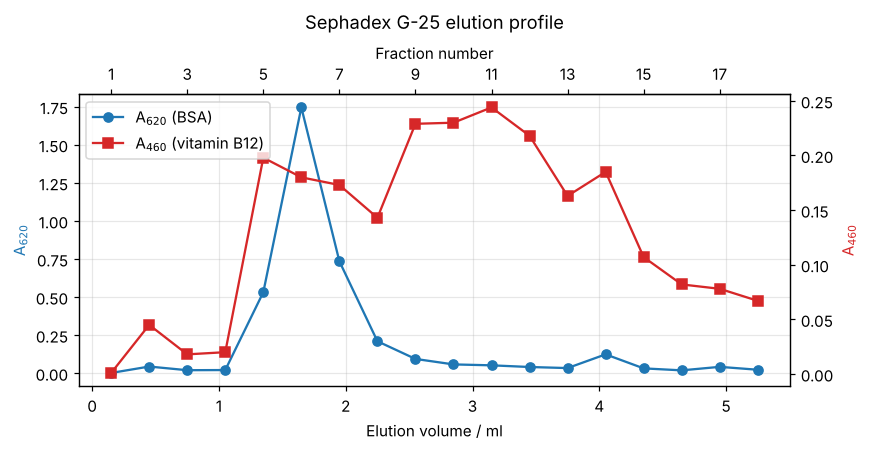

In [3]:
fig, ax1 = plt.subplots(figsize=(8, 4.2))
ax1.plot(df["V_ml"], df["A620"], "o-", c="C0", label="A$_{620}$ (BSA)")
ax1.set_xlabel("Elution volume / ml"); ax1.set_ylabel("A$_{620}$", color="C0")
ax2 = ax1.twinx()
ax2.plot(df["V_ml"], df["A460"], "s-", c="C3", label="A$_{460}$ (vitamin B12)")
ax2.set_ylabel("A$_{460}$", color="C3"); ax2.grid(False)
secx = ax1.secondary_xaxis("top", functions=(lambda v: v/frac_ml + 0.5, lambda f: (f-0.5)*frac_ml))
secx.set_xlabel("Fraction number"); secx.set_xticks(range(1, 19, 2))
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, loc="upper left")
ax1.set_title("Sephadex G-25 elution profile", pad=10)
plt.tight_layout(); plt.show()

## 3. Peak identification

Size exclusion separates by size. Large molecules can't enter the gel pores, so they take the shortest path and elute first. Small molecules spend time inside the pores and elute later. I expect BSA first and B12 second.

I locate each peak at its maximum and also calculate a **centroid** (absorbance-weighted mean volume) over the peak region. The centroid is less sensitive to which single fraction happened to be collected at the top.

In [4]:
def centroid(sub, col):
    w = sub[col].to_numpy(); v = sub["V_ml"].to_numpy()
    return (w * v).sum() / w.sum()

bsa_win = df[df["fraction"].between(4, 9)]
b12_win = df[df["fraction"].between(8, 18)]

peaks = pd.DataFrame([
    {"species": "BSA (A620)", "max fraction": int(df.loc[df["A620"].idxmax(), "fraction"]),
     "max A": df["A620"].max(), "centroid V / ml": centroid(bsa_win, "A620")},
    {"species": "Vitamin B12 (A460)", "max fraction": int(b12_win.loc[b12_win["A460"].idxmax(), "fraction"]),
     "max A": b12_win["A460"].max(), "centroid V / ml": centroid(b12_win, "A460")},
])
peaks["peak gap / ml"] = peaks["centroid V / ml"] - peaks["centroid V / ml"].iloc[0]
peaks.round(3)

,species,max fraction,max A,centroid V / ml,peak gap / ml
0,BSA (A620),6,1.745,1.728,0.000
1,Vitamin B12 (A460),11,0.244,3.452,1.724


As expected, BSA elutes first (a sharp peak at fraction 6) and vitamin B12 later (a broad peak around fractions 9–12). The B12 band is much wider than the BSA band. Small molecules spread out more inside the gel because they diffuse in and out of the pores along the way.

## 4. Flagging artefacts

A genuine elution band should rise and fall smoothly over several fractions. A single fraction that jumps at **both** wavelengths at once, and doesn't fit either band's shape, more likely comes from the cuvette than the column, for example an air bubble, a fingerprint or scattering from particles.

My rule: flag a fraction if **one wavelength jumps to more than double the average of its neighbours** (a spike > 100%) **and the other wavelength also rises by more than 20%** at the same time. Requiring both stops the real BSA peak at fraction 6 being flagged, because its A620 spikes but its A460 doesn't.

In [5]:
def spike(col):
    s = df[col]
    neighbours = (s.shift(1) + s.shift(-1)) / 2
    return (s - neighbours) / neighbours

df["spike460"], df["spike620"] = spike("A460"), spike("A620")
big = df[["spike460", "spike620"]].max(axis=1)
small = df[["spike460", "spike620"]].min(axis=1)
df["artefact?"] = (big > 1.0) & (small > 0.2)
df.loc[df["artefact?"], ["fraction", "A460", "A620", "spike460", "spike620"]].round(2)

,fraction,A460,A620,spike460,spike620
1,2,0.04,0.04,3.74,3.00
13,14,0.18,0.12,0.37,2.76


- **Fraction 2:** both wavelengths read about 0.045, about equal, in a region where nothing should have eluted yet. Equal absorbance at very different wavelengths points to non-specific light scattering, not either coloured compound.
- **Fraction 14:** A620 jumps from 0.034 to 0.124 and back to 0.032, and A460 bumps at the same time. BSA can't reappear in the middle of the B12 band, so this is almost certainly an artefact. I mentioned this "deviation" in my original report, and now there's an objective rule for it.

Flagged fractions are excluded from the pooling decision below.

## 5. How specific is each wavelength?

The two wavelengths are meant to track one compound each. But **A460 is far from zero under the BSA peak**: about 0.18–0.20 in fractions 5–7, around 80% of B12's own peak height.

To compare the two traces fairly, I normalise each to its own maximum and calculate a simple **B12 specificity index** for each fraction:

  **index = n₄₆₀ / (n₄₆₀ + n₆₂₀)**, where n is the normalised absorbance

A value near 1 means the fraction is dominated by the B12 signal. Near 0.5 means both signals are equally strong.

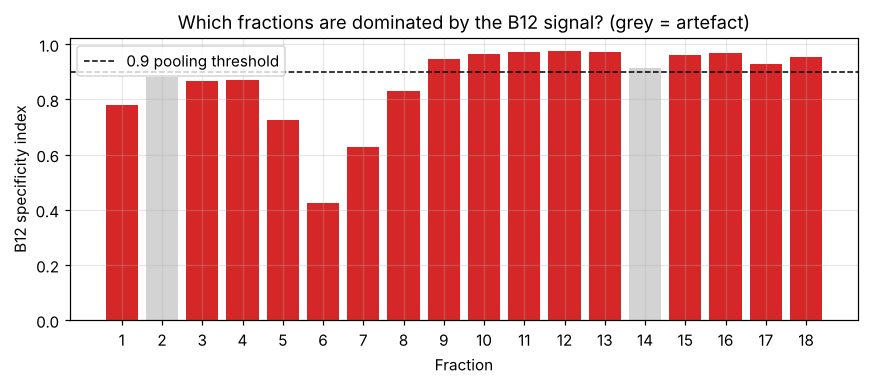

In [6]:
df["n460"] = df["A460"] / df["A460"].max()
df["n620"] = df["A620"] / df["A620"].max()
df["B12_index"] = df["n460"] / (df["n460"] + df["n620"])

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(df["fraction"], df["B12_index"], color=np.where(df["artefact?"], "lightgrey", "C3"))
ax.axhline(0.9, ls="--", c="k", lw=1, label="0.9 pooling threshold")
ax.set_xlabel("Fraction"); ax.set_ylabel("B12 specificity index"); ax.set_xticks(df["fraction"])
ax.set_title("Which fractions are dominated by the B12 signal? (grey = artefact)")
ax.legend(); plt.tight_layout(); plt.show()

Fractions 5–7 have a low index even though A460 is high there, so their 460 nm signal comes with a lot of 620 nm signal. Two explanations are possible, and this dataset can't tell them apart:

1. **Partial co-elution:** some B12 travels with the BSA band (poor resolution), or
2. **Spectral overlap:** the BSA/dye species also absorbs at 460 nm, so A460 isn't specific to B12.

**How I'd resolve it:** measure pure BSA and pure B12 standards at both wavelengths, then solve the two-component Beer-Lambert simultaneous equations for each fraction:

  A₄₆₀ = ε₄₆₀(B12)·c(B12) + ε₄₆₀(BSA)·c(BSA)
  A₆₂₀ = ε₆₂₀(B12)·c(B12) + ε₆₂₀(BSA)·c(BSA)

This is the same idea as **peak-purity analysis with a diode-array detector in HPLC**: using more than one wavelength to check whether a peak really is a single compound.

## 6. Pooling decision for vitamin B12

In purification there's always a **yield-purity trade-off**. Pool more fractions and you recover more product, but you also pull in more contaminant. My pooling rule:
- the fraction isn't flagged as an artefact
- the B12 specificity index is ≥ 0.9
- the A460 is at least 50% of the B12 peak (to avoid diluting the pool with near-empty fractions)

In [7]:
total_b12 = df.loc[~df["artefact?"] & df["fraction"].between(8, 18), "A460"].sum()

df["pool"] = (~df["artefact?"]) & (df["B12_index"] >= 0.9) & (df["n460"] >= 0.5)
pool = df[df["pool"]]
recovery = pool["A460"].sum() / total_b12 * 100

print("Fractions to pool:", pool["fraction"].tolist())
print(f"Pooled volume: {len(pool)*frac_ml:.1f} ml of eluate")
print(f"Share of the B12 band (fractions 8–18, artefacts excluded) recovered: {recovery:.0f}%")
print(f"Lowest B12 index in the pool: {pool['B12_index'].min():.2f}")

Fractions to pool: [9, 10, 11, 12, 13]
Pooled volume: 1.5 ml of eluate
Share of the B12 band (fractions 8–18, artefacts excluded) recovered: 69%
Lowest B12 index in the pool: 0.95


In [8]:
# Show the trade-off: what if I relax or tighten the peak-height cut-off?
rows = []
for cut in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    sel = (~df["artefact?"]) & (df["B12_index"] >= 0.9) & (df["n460"] >= cut)
    rows.append({"min height (fraction of peak)": cut,
                 "fractions": df.loc[sel, "fraction"].tolist(),
                 "recovery %": round(df.loc[sel, "A460"].sum() / total_b12 * 100),
                 "pooled ml": round(sel.sum() * frac_ml, 1)})
pd.DataFrame(rows)

,min height (fraction of peak),fractions,recovery %,pooled ml
0,0.3,"[9, 10, 11, 12, 13, 15, 16, 17]",87,2.4
1,0.4,"[9, 10, 11, 12, 13, 15]",76,1.8
2,0.5,"[9, 10, 11, 12, 13]",69,1.5
3,0.6,"[9, 10, 11, 12, 13]",69,1.5
4,0.7,"[9, 10, 11, 12]",59,1.2
5,0.8,"[9, 10, 11, 12]",59,1.2
6,0.9,"[9, 10, 11]",45,0.9


**Decision:** pool **fractions 9–13**. This takes the core of the B12 band, where the 460 nm signal is strong and the 620 nm signal has fallen to its baseline. It leaves out fraction 14 (artefact) and the dilute tail (15–18). That agrees with my original report, which picked fractions 12–13 as the purest. The analysis here gives a reason for the choice and shows what each extra fraction would add in recovery.

For BSA, only fraction 6 stands out clearly. Its neighbours carry substantial 460 nm signal, so the BSA pool would be either small (fraction 6 only) or noticeably less pure.

## Summary

| Result | Finding |
|---|---|
| Elution order | BSA first (fraction 6), B12 later (fractions 9–12): consistent with size exclusion |
| B12 band | much broader than the BSA band (diffusion into the gel pores) |
| Artefacts | fractions 2 and 14, both signals spiking together |
| Wavelength specificity | A460 is not specific: there's strong 460 nm signal under the BSA peak |
| B12 pool | fractions 9–13 (≈ 69% of the B12 band, 1.5 ml) |
| Recommended next step | two-component Beer-Lambert with pure standards (the same principle as DAD peak purity) |

**What I learned:** reading a chromatogram is more than finding the tallest point. Objective peak positions, artefact rules and checking that a detector signal is really specific to one compound all change which fractions you'd trust. The same applies to HPLC data in a QC lab.